### Loading the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load original datasets
train = pd.read_csv("credit_train.csv")
test = pd.read_csv("credit_test.csv")

# Keep untouched copies of the raw data
train_raw = train.copy(deep=True)
test_raw = test.copy(deep=True)

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

Training shape: (100514, 19)
Testing shape: (10353, 18)


### Inspect structure and data types

In [2]:
# View sample records
print(train.head())

# Check column names, data types, and non-null counts
train.info()

# Review numerical statistics
print(train.describe().T)

                                Loan ID                           Customer ID  \
0  14dd8831-6af5-400b-83ec-68e61888a048  981165ec-3274-42f5-a3b4-d104041a9ca9   
1  4771cc26-131a-45db-b5aa-537ea4ba5342  2de017a3-2e01-49cb-a581-08169e83be29   
2  4eed4e6a-aa2f-4c91-8651-ce984ee8fb26  5efb2b2b-bf11-4dfd-a572-3761a2694725   
3  77598f7b-32e7-4e3b-a6e5-06ba0d98fe8a  e777faab-98ae-45af-9a86-7ce5b33b1011   
4  d4062e70-befa-4995-8643-a0de73938182  81536ad9-5ccf-4eb8-befb-47a4d608658e   

  Loan Status  Current Loan Amount        Term  Credit Score  Annual Income  \
0  Fully Paid             445412.0  Short Term         709.0      1167493.0   
1  Fully Paid             262328.0  Short Term           NaN            NaN   
2  Fully Paid           99999999.0  Short Term         741.0      2231892.0   
3  Fully Paid             347666.0   Long Term         721.0       806949.0   
4  Fully Paid             176220.0  Short Term           NaN            NaN   

  Years in current job Home Ownership 

### Check missing values

In [3]:
# Count missing values in each column
missing = train.isnull().sum()

# Calculate missing-value percentage
missing_pct = (missing / len(train) * 100).round(2)

missing_report = pd.DataFrame({
    "Missing_Count": missing,
    "Missing_Percentage": missing_pct
})

print(missing_report.sort_values(
    "Missing_Percentage", ascending=False
))

                              Missing_Count  Missing_Percentage
Months since last delinquent          53655               53.38
Annual Income                         19668               19.57
Credit Score                          19668               19.57
Years in current job                   4736                4.71
Bankruptcies                            718                0.71
Tax Liens                               524                0.52
Loan ID                                 514                0.51
Loan Status                             514                0.51
Customer ID                             514                0.51
Current Loan Amount                     514                0.51
Term                                    514                0.51
Monthly Debt                            514                0.51
Purpose                                 514                0.51
Home Ownership                          514                0.51
Years of Credit History                 

### Investigate suspicious values

In [4]:
# Examine unusual loan amounts
print(
    train.loc[
        train["Current Loan Amount"] > 10_000_000,
        "Current Loan Amount"
    ].value_counts()
)

# Examine unusually high credit scores
print(
    train.loc[
        train["Credit Score"] > 850,
        "Credit Score"
    ].value_counts().sort_index()
)

Current Loan Amount
99999999.0    11484
Name: count, dtype: int64
Credit Score
5850.0     2
5860.0     1
5890.0     1
5900.0     1
5920.0     1
          ..
7470.0    51
7480.0    43
7490.0    23
7500.0    24
7510.0     9
Name: count, Length: 157, dtype: int64


### Standardize inconsistent categories

In [5]:
# Standardize text formatting
for df in [train, test]:
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()

# Inspect categories before merging any values
print(train["Purpose"].value_counts(dropna=False))
print(train["Home Ownership"].value_counts(dropna=False))

Purpose
Debt Consolidation      78552
other                    6037
Home Improvements        5839
Other                    3250
Business Loan            1569
Buy a Car                1265
Medical Bills            1127
Buy House                 678
Take a Trip               573
NaN                       514
major_purchase            352
small_business            283
moving                    150
wedding                   115
vacation                  101
Educational Expenses       99
renewable_energy           10
Name: count, dtype: int64
Home Ownership
Home Mortgage    48410
Rent             42194
Own Home          9182
NaN                514
HaveMortgage       214
Name: count, dtype: int64


C:\Users\ASUS\AppData\Local\Temp\ipykernel_21256\4117487671.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:
C:\Users\ASUS\AppData\Local\Temp\ipykernel_21256\4117487671.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/mi

### Validate the cleaned data

In [6]:
# Check remaining missing values
print(train.isnull().sum().sort_values(ascending=False))

# Check data types
print(train.dtypes)

# Confirm blank rows are gone
print("Blank rows remaining:", train.isnull().all(axis=1).sum())

# Compare dataset dimensions
print("Clean training shape:", train.shape)
print("Clean test shape:", test.shape)

Months since last delinquent    53655
Annual Income                   19668
Credit Score                    19668
Years in current job             4736
Bankruptcies                      718
Tax Liens                         524
Maximum Open Credit               516
Loan Status                       514
Customer ID                       514
Loan ID                           514
Term                              514
Monthly Debt                      514
Purpose                           514
Home Ownership                    514
Current Loan Amount               514
Number of Credit Problems         514
Number of Open Accounts           514
Years of Credit History           514
Current Credit Balance            514
dtype: int64
Loan ID                             str
Customer ID                         str
Loan Status                         str
Current Loan Amount             float64
Term                                str
Credit Score                    float64
Annual Income            

### Investigate duplicate loan IDs

In [7]:
# Remove completely blank rows from working copies
train = train_raw.dropna(how="all").copy()
test = test_raw.dropna(how="all").copy()

# Count exact duplicate rows
print("Exact duplicate rows:", train.duplicated().sum())

# Inspect repeated loan IDs
duplicate_loans = train[
    train["Loan ID"].duplicated(keep=False)
].sort_values("Loan ID")

print("Rows with repeated loan IDs:", len(duplicate_loans))
print("Distinct repeated loan IDs:", duplicate_loans["Loan ID"].nunique())

# Inspect a sample of repeated IDs
print(duplicate_loans.head(10).to_string(index=False))

Exact duplicate rows: 10215
Rows with repeated loan IDs: 36002
Distinct repeated loan IDs: 18001
                             Loan ID                          Customer ID Loan Status  Current Loan Amount       Term  Credit Score  Annual Income Years in current job Home Ownership            Purpose  Monthly Debt  Years of Credit History  Months since last delinquent  Number of Open Accounts  Number of Credit Problems  Current Credit Balance  Maximum Open Credit  Bankruptcies  Tax Liens
00069ff1-a877-4d35-81be-7cd359b99956 ee3c27f2-766a-499c-9a96-d17c4d2faa16  Fully Paid              31526.0 Short Term         716.0      2065965.0            10+ years  Home Mortgage  Home Improvements      49927.44                     15.1                           5.0                     22.0                        0.0                526414.0            1090386.0           0.0        0.0
00069ff1-a877-4d35-81be-7cd359b99956 ee3c27f2-766a-499c-9a96-d17c4d2faa16  Fully Paid              31526.0 Short Term

### Handle confirmed duplicate records

In [8]:
# Record how many exact duplicate rows exist
exact_duplicates = train.duplicated().sum()

# Remove exact duplicate records
train = train.drop_duplicates().copy()

print("Exact duplicates removed:", exact_duplicates)
print("Rows remaining:", len(train))

# Recheck repeated loan IDs; these need separate investigation
print("Repeated loan IDs remaining:",
      train["Loan ID"].duplicated().sum())

Exact duplicates removed: 10215
Rows remaining: 89785
Repeated loan IDs remaining: 7786


### Correct confirmed data-quality issuse

In [9]:
# Count the suspicious values before any changes
print(
    "Special loan amount values:",
    (train["Current Loan Amount"] == 99_999_999).sum()
)

print(
    "Credit scores above 850:",
    (train["Credit Score"] > 850).sum()
)

# Correct credit scores only if verification confirms
# that affected scores were multiplied by 10.
# Do not apply this transformation blindly.

Special loan amount values: 11484
Credit scores above 850: 4551


### Standardize categories and save

In [11]:
# Remove leading and trailing spaces from text columns
for df in [train, test]:
    text_cols = df.select_dtypes(
        include=["object", "str", "string"]
    ).columns

    for col in text_cols:
        df[col] = df[col].str.strip()

# Standardize categories
for df in [train, test]:
    df["Purpose"] = df["Purpose"].replace({
        "other": "Other"
    })

    df["Home Ownership"] = df["Home Ownership"].replace({
        "HaveMortgage": "Home Mortgage"
    })

# Save the cleaned working datasets
train.to_csv("credit_train_cleaned.csv", index=False)
test.to_csv("credit_test_cleaned.csv", index=False)

print("Category standardization completed successfully.")

Category standardization completed successfully.


### Run the final quality report

In [12]:
import numpy as np
import pandas as pd

# 1. Check dataset dimensions
print("TRAINING DATA:", train.shape)
print("TEST DATA:", test.shape)

# 2. Check missing values
missing_report = pd.DataFrame({
    "Missing_Count": train.isna().sum(),
    "Missing_Percentage": (
        train.isna().mean() * 100
    ).round(2)
})

print("\nMISSING VALUE REPORT")
print(
    missing_report
    .sort_values("Missing_Percentage", ascending=False)
)

# 3. Check exact duplicates
print("\nEXACT DUPLICATES")
print("Train:", train.duplicated().sum())
print("Test:", test.duplicated().sum())

# 4. Check duplicate loan IDs
print("\nDUPLICATE LOAN IDS")
print("Train:", train["Loan ID"].duplicated().sum())
print("Test:", test["Loan ID"].duplicated().sum())

# 5. Check target values
print("\nLOAN STATUS DISTRIBUTION")
print(train["Loan Status"].value_counts(dropna=False))

# 6. Check suspicious numerical values
print("\nCURRENT LOAN AMOUNT")
print(train["Current Loan Amount"].describe())

print("\nCREDIT SCORE")
print(train["Credit Score"].describe())

# 7. Check whether completely blank rows remain
print("\nCOMPLETELY BLANK ROWS")
print("Train:", train.isna().all(axis=1).sum())
print("Test:", test.isna().all(axis=1).sum())

TRAINING DATA: (89785, 19)
TEST DATA: (10000, 18)

MISSING VALUE REPORT
                              Missing_Count  Missing_Percentage
Months since last delinquent          48337               53.84
Annual Income                         19154               21.33
Credit Score                          19154               21.33
Years in current job                   3802                4.23
Bankruptcies                            190                0.21
Tax Liens                                 9                0.01
Loan ID                                   0                0.00
Loan Status                               0                0.00
Customer ID                               0                0.00
Current Loan Amount                       0                0.00
Term                                      0                0.00
Monthly Debt                              0                0.00
Purpose                                   0                0.00
Home Ownership                  

### Understand loan repayment outcomes

In [13]:
# Remove completely blank rows for analysis
eda = train.dropna(how="all").copy()

# Calculate the number of loans in each category
loan_counts = eda["Loan Status"].value_counts()

# Calculate the percentage of each outcome
loan_percentages = (
    eda["Loan Status"].value_counts(normalize=True) * 100
).round(2)

print("Loan Counts:")
print(loan_counts)

print("\nLoan Outcome Percentages:")
print(loan_percentages)

Loan Counts:
Loan Status
Fully Paid     67146
Charged Off    22639
Name: count, dtype: int64

Loan Outcome Percentages:
Loan Status
Fully Paid     74.79
Charged Off    25.21
Name: proportion, dtype: float64


### Create your first matplotlib chart

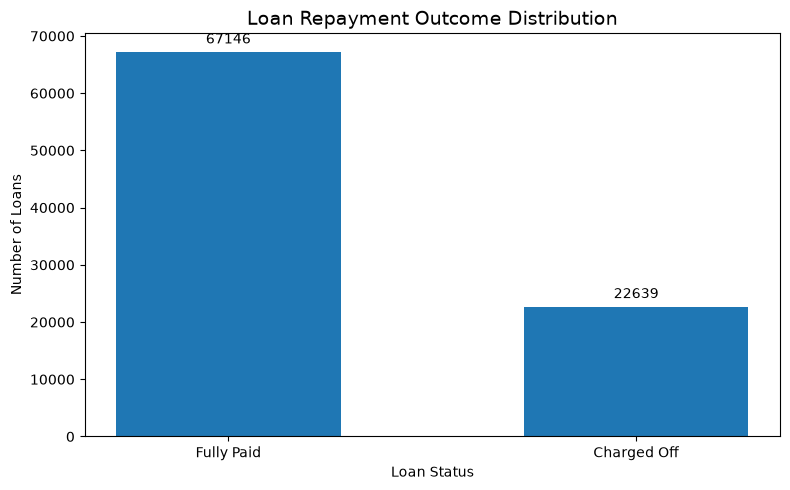

In [14]:
# Calculate loan outcome counts
loan_counts = eda["Loan Status"].value_counts()

# Create a bar chart
plt.figure(figsize=(8, 5))
bars = plt.bar(
    loan_counts.index,
    loan_counts.values,
    width=0.55
)

# Add labels and formatting
plt.title("Loan Repayment Outcome Distribution", fontsize=14)
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")
plt.bar_label(bars, fmt="%.0f", padding=4)

plt.tight_layout()
plt.show()

### Understand the numerical variables

In [15]:
numeric_cols = [
    "Current Loan Amount",
    "Credit Score",
    "Annual Income",
    "Monthly Debt",
    "Years of Credit History",
    "Current Credit Balance"
]

summary = eda[numeric_cols].describe().T

summary["Median"] = eda[numeric_cols].median()
summary["Missing_Percent"] = (
    eda[numeric_cols].isna().mean() * 100
).round(2)

print(summary.round(2))

                           count         mean          std      min       25%  \
Current Loan Amount      89785.0  13060894.72  33295559.59  10802.0  180268.0   
Credit Score             70631.0      1130.83      1571.04    585.0     708.0   
Annual Income            70631.0   1375894.39   1104851.70  76627.0  847932.0   
Monthly Debt             89785.0     18396.91     12145.28      0.0   10157.4   
Years of Credit History  89785.0        18.25         7.03      3.6      13.5   
Current Credit Balance   89785.0    294035.13    372227.70      0.0  112936.0   

                                50%         75%           max      Median  \
Current Loan Amount       313874.00   532378.00  1.000000e+08   313874.00   
Credit Score                 729.00      742.00  7.510000e+03      729.00   
Annual Income            1168975.00  1648915.00  1.655574e+08  1168975.00   
Monthly Debt               16140.31    23918.91  4.358433e+05    16140.31   
Years of Credit History       17.00       21.70

### Compare credite scores by loan outcome

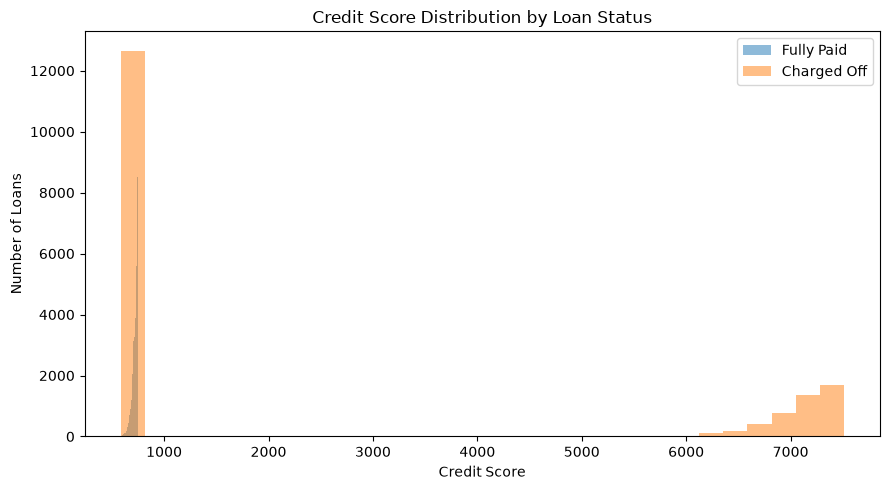

In [16]:
# Compare credit score distributions across loan outcomes
plt.figure(figsize=(9, 5))

for status in eda["Loan Status"].dropna().unique():
    scores = eda.loc[
        eda["Loan Status"] == status,
        "Credit Score"
    ].dropna()

    plt.hist(
        scores,
        bins=30,
        alpha=0.5,
        label=status
    )

plt.title("Credit Score Distribution by Loan Status")
plt.xlabel("Credit Score")
plt.ylabel("Number of Loans")
plt.legend()
plt.tight_layout()
plt.show()

### Compare annual income by loan outcome

             count        mean     median
Loan Status                              
Charged Off  17210  1267789.54  1085812.0
Fully Paid   53421  1410721.22  1215620.0


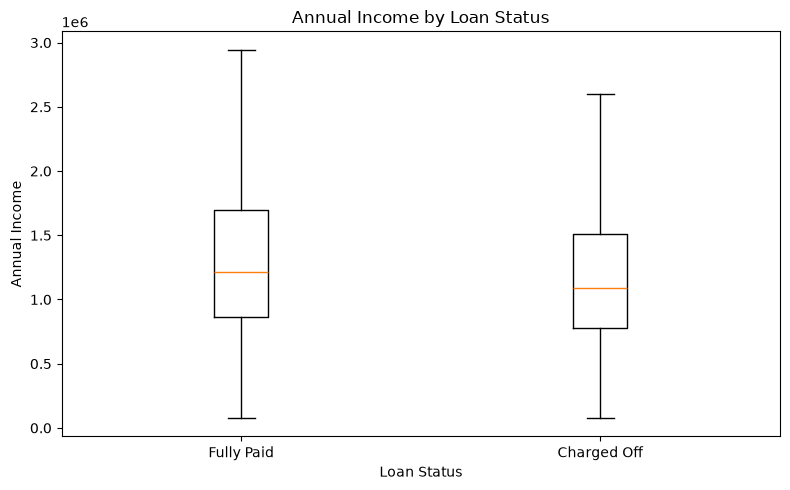

In [17]:
# Summarize income by repayment outcome
income_summary = eda.groupby("Loan Status")["Annual Income"].agg(
    ["count", "mean", "median"]
)

print(income_summary.round(2))

# Compare income distributions using box plots
income_groups = [
    eda.loc[
        eda["Loan Status"] == status,
        "Annual Income"
    ].dropna()
    for status in ["Fully Paid", "Charged Off"]
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    income_groups,
    tick_labels=["Fully Paid", "Charged Off"],
    showfliers=False
)

plt.title("Annual Income by Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Annual Income")
plt.tight_layout()
plt.show()

### compare loan outcomes by loan term

Loan Status  Charged Off  Fully Paid
Term                                
Long Term          35.21       64.79
Short Term         21.62       78.38


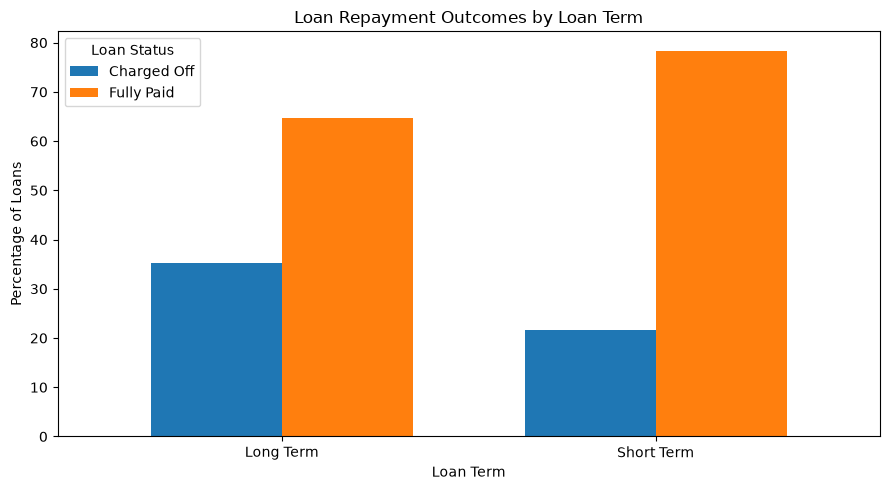

In [18]:
# Calculate repayment percentages within each loan term
term_analysis = pd.crosstab(
    eda["Term"],
    eda["Loan Status"],
    normalize="index"
) * 100

print(term_analysis.round(2))

# Visualize the percentages
term_analysis.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Loan Repayment Outcomes by Loan Term")
plt.xlabel("Loan Term")
plt.ylabel("Percentage of Loans")
plt.xticks(rotation=0)
plt.legend(title="Loan Status")
plt.tight_layout()
plt.show()

### Analyze loan purpose

Loan Status           Charged Off  Fully Paid
Purpose                                      
renewable_energy            50.00       50.00
small_business              46.67       53.33
Business Loan               34.99       65.01
vacation                    32.58       67.42
moving                      31.85       68.15
Medical Bills               28.28       71.72
Debt Consolidation          25.30       74.70
Other                       24.96       75.04
major_purchase              24.85       75.15
Buy House                   24.05       75.95
Take a Trip                 23.57       76.43
Home Improvements           22.21       77.79
wedding                     21.90       78.10
Educational Expenses        19.78       80.22
Buy a Car                   17.42       82.58


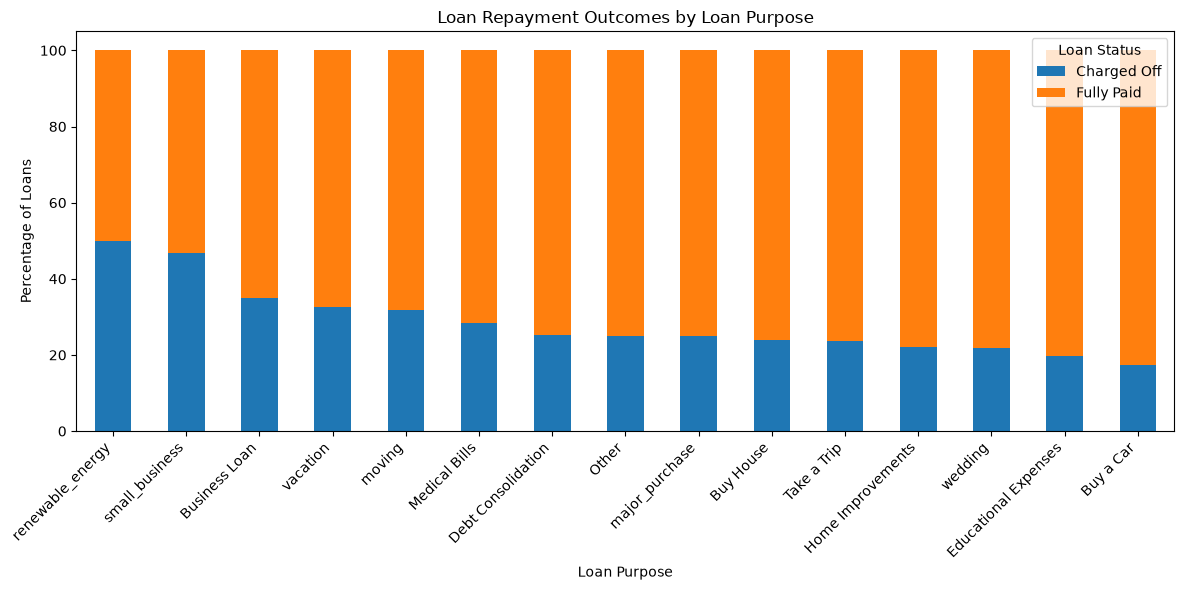

In [19]:
# Compare loan outcomes by purpose
purpose_analysis = pd.crosstab(
    eda["Purpose"],
    eda["Loan Status"],
    normalize="index"
) * 100

# Sort by charged-off percentage, if available
if "Charged Off" in purpose_analysis.columns:
    purpose_analysis = purpose_analysis.sort_values(
        "Charged Off",
        ascending=False
    )

print(purpose_analysis.round(2))

# Plot the results
purpose_analysis.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Loan Repayment Outcomes by Loan Purpose")
plt.xlabel("Loan Purpose")
plt.ylabel("Percentage of Loans")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Loan Status")
plt.tight_layout()
plt.show()

### Investigate debt-to-income ratio

             count  median   mean
Loan Status                      
Charged Off  17210    18.5  18.78
Fully Paid   53421    16.3  16.67


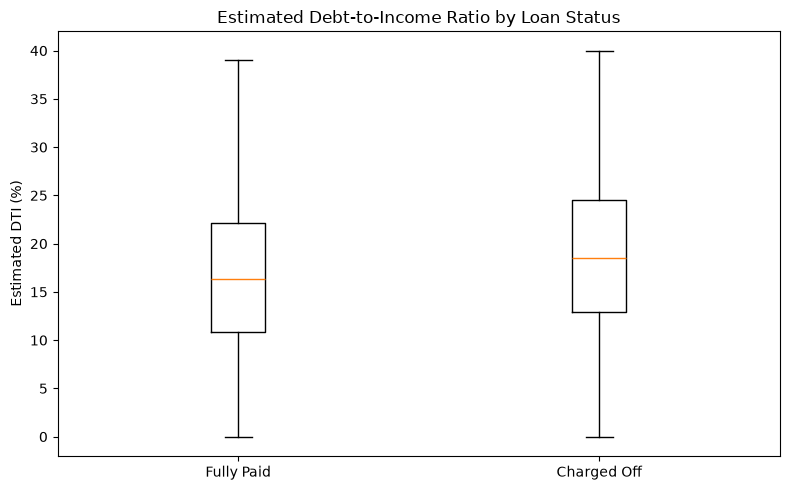

In [20]:
# Create a working copy for this analysis
dti_data = eda.copy()

# Avoid division by zero and invalid income values
valid_income = dti_data["Annual Income"] > 0

dti_data["DTI_Percent"] = np.where(
    valid_income,
    dti_data["Monthly Debt"] /
    (dti_data["Annual Income"] / 12) * 100,
    np.nan
)

# Summarize DTI by loan outcome
dti_summary = dti_data.groupby("Loan Status")[
    "DTI_Percent"
].agg(["count", "median", "mean"])

print(dti_summary.round(2))

# Compare distributions using a box plot
dti_groups = [
    dti_data.loc[
        dti_data["Loan Status"] == status,
        "DTI_Percent"
    ].dropna()
    for status in ["Fully Paid", "Charged Off"]
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    dti_groups,
    tick_labels=["Fully Paid", "Charged Off"],
    showfliers=False
)

plt.title("Estimated Debt-to-Income Ratio by Loan Status")
plt.ylabel("Estimated DTI (%)")
plt.tight_layout()
plt.show()

### Analyze credit history

             count  median   mean
Loan Status                      
Charged Off  22639    16.6  17.89
Fully Paid   67146    17.0  18.37


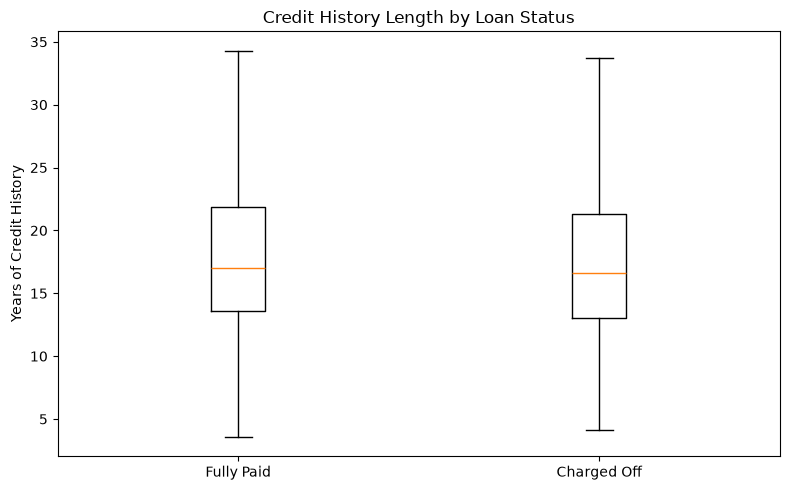

In [21]:
# Summarize credit history by outcome
history_summary = eda.groupby("Loan Status")[
    "Years of Credit History"
].agg(["count", "median", "mean"])

print(history_summary.round(2))

# Compare distributions
history_groups = [
    eda.loc[
        eda["Loan Status"] == status,
        "Years of Credit History"
    ].dropna()
    for status in ["Fully Paid", "Charged Off"]
]

plt.figure(figsize=(8, 5))
plt.boxplot(
    history_groups,
    tick_labels=["Fully Paid", "Charged Off"],
    showfliers=False
)

plt.title("Credit History Length by Loan Status")
plt.ylabel("Years of Credit History")
plt.tight_layout()
plt.show()

### Build a business KPI summary

In [22]:
# Exclude records without a known loan outcome
valid_outcomes = eda.dropna(subset=["Loan Status"]).copy()

total_loans = len(valid_outcomes)

fully_paid = (
    valid_outcomes["Loan Status"] == "Fully Paid"
).sum()

charged_off = (
    valid_outcomes["Loan Status"] == "Charged Off"
).sum()

kpis = pd.Series({
    "Loans with Known Outcome": total_loans,
    "Fully Paid Loans": fully_paid,
    "Charged Off Loans": charged_off,
    "Fully Paid Rate (%)": (
        fully_paid / total_loans * 100
        if total_loans else np.nan
    ),
    "Charged Off Rate (%)": (
        charged_off / total_loans * 100
        if total_loans else np.nan
    )
})

print(kpis.round(2))

Loans with Known Outcome    89785.00
Fully Paid Loans            67146.00
Charged Off Loans           22639.00
Fully Paid Rate (%)            74.79
Charged Off Rate (%)           25.21
dtype: float64


### Create the dashboard in python

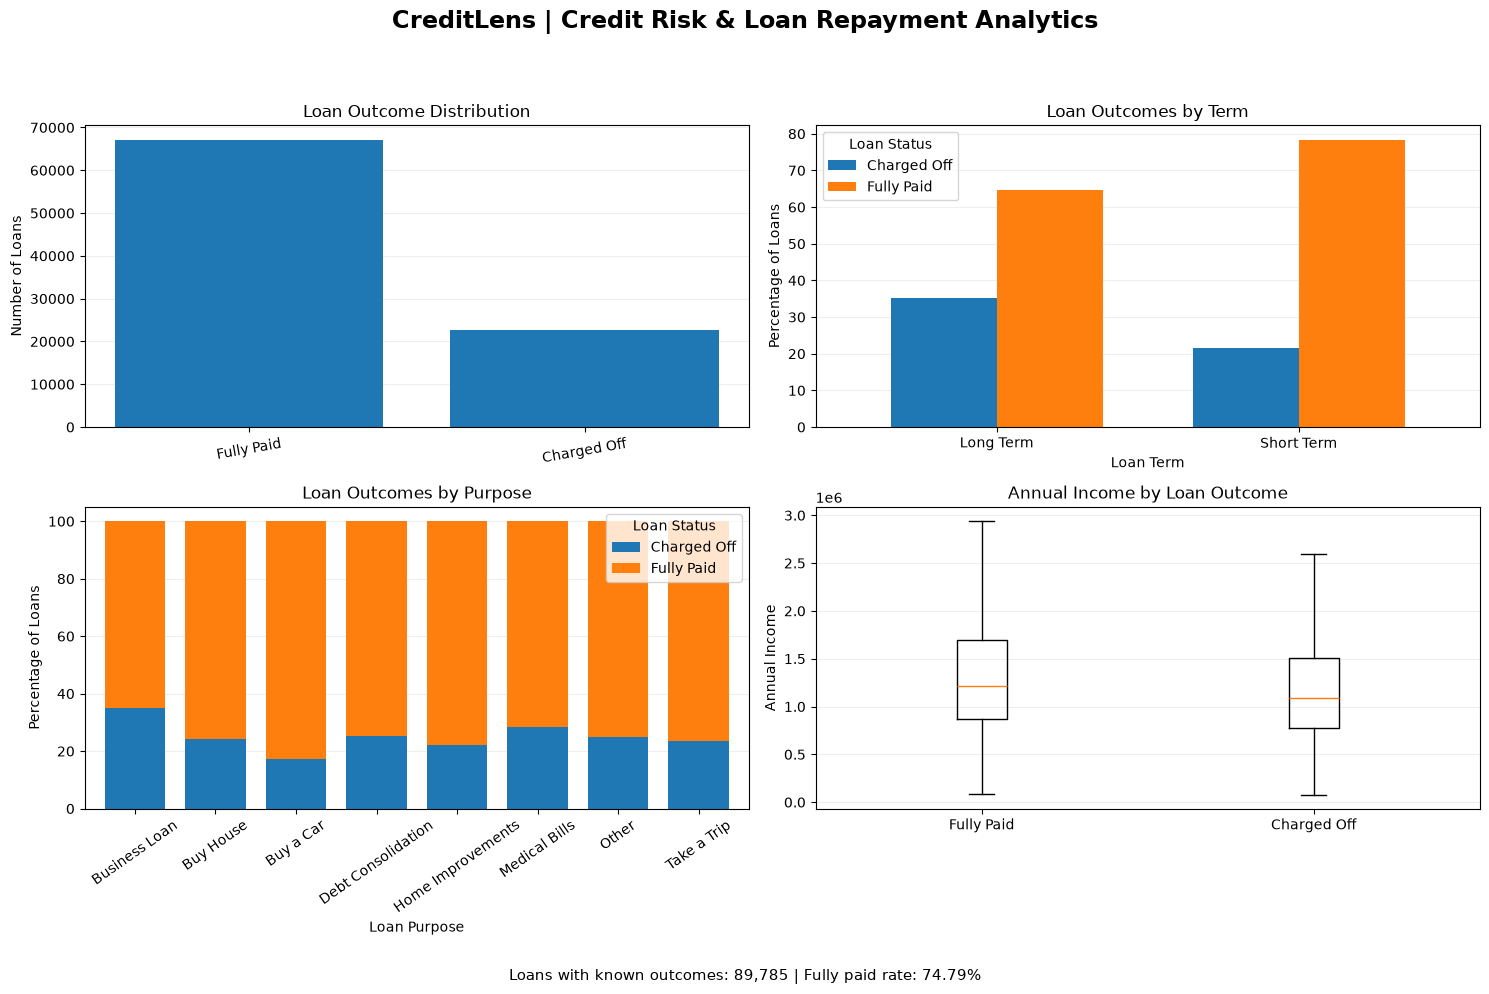

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use records with known loan outcomes
dashboard_data = eda.dropna(subset=["Loan Status"]).copy()

# Calculate overall KPIs
total_loans = len(dashboard_data)
paid_rate = (
    dashboard_data["Loan Status"].eq("Fully Paid").mean() * 100
    if total_loans else 0
)

# Create a 2x2 dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle(
    "CreditLens | Credit Risk & Loan Repayment Analytics",
    fontsize=17,
    fontweight="bold"
)

# Chart 1: Loan outcome distribution
outcome_counts = dashboard_data["Loan Status"].value_counts()

axes[0, 0].bar(
    outcome_counts.index,
    outcome_counts.values
)
axes[0, 0].set_title("Loan Outcome Distribution")
axes[0, 0].set_ylabel("Number of Loans")
axes[0, 0].tick_params(axis="x", rotation=10)

# Chart 2: Outcome by loan term
term_table = pd.crosstab(
    dashboard_data["Term"],
    dashboard_data["Loan Status"],
    normalize="index"
) * 100

term_table.plot(
    kind="bar",
    ax=axes[0, 1],
    width=0.7
)
axes[0, 1].set_title("Loan Outcomes by Term")
axes[0, 1].set_ylabel("Percentage of Loans")
axes[0, 1].set_xlabel("Loan Term")
axes[0, 1].tick_params(axis="x", rotation=0)

# Chart 3: Outcome by most common loan purposes
top_purposes = (
    dashboard_data["Purpose"]
    .value_counts()
    .head(8)
    .index
)

purpose_table = pd.crosstab(
    dashboard_data.loc[
        dashboard_data["Purpose"].isin(top_purposes),
        "Purpose"
    ],
    dashboard_data.loc[
        dashboard_data["Purpose"].isin(top_purposes),
        "Loan Status"
    ],
    normalize="index"
) * 100

purpose_table.plot(
    kind="bar",
    stacked=True,
    ax=axes[1, 0],
    width=0.75
)
axes[1, 0].set_title("Loan Outcomes by Purpose")
axes[1, 0].set_ylabel("Percentage of Loans")
axes[1, 0].set_xlabel("Loan Purpose")
axes[1, 0].tick_params(axis="x", rotation=35)

# Chart 4: Annual income by outcome
income_groups = [
    dashboard_data.loc[
        dashboard_data["Loan Status"] == status,
        "Annual Income"
    ].dropna()
    for status in ["Fully Paid", "Charged Off"]
]

axes[1, 1].boxplot(
    income_groups,
    tick_labels=["Fully Paid", "Charged Off"],
    showfliers=False
)
axes[1, 1].set_title("Annual Income by Loan Outcome")
axes[1, 1].set_ylabel("Annual Income")

# Improve spacing and readability
for ax in axes.flat:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.text(
    0.5, 0.01,
    f"Loans with known outcomes: {total_loans:,} | "
    f"Fully paid rate: {paid_rate:.2f}%",
    ha="center",
    fontsize=11
)

plt.tight_layout(rect=[0, 0.04, 1, 0.94])
plt.show()

### Generate evidence for you business recommendation

In [24]:
# Overall repayment outcomes
eda = train.dropna(subset=["Loan Status"]).copy()

outcome_report = eda["Loan Status"].value_counts().to_frame(
    "Loan_Count"
)
outcome_report["Percentage"] = (
    eda["Loan Status"].value_counts(normalize=True) * 100
).round(2)

print("OVERALL LOAN OUTCOMES")
print(outcome_report)

# Outcome rates by loan term
term_report = pd.crosstab(
    eda["Term"],
    eda["Loan Status"]
)

term_report["Total_Loans"] = term_report.sum(axis=1)

if "Charged Off" in term_report.columns:
    term_report["Charged_Off_Rate"] = (
        term_report["Charged Off"] /
        term_report["Total_Loans"] * 100
    ).round(2)

print("\nOUTCOMES BY LOAN TERM")
print(term_report)

# Outcome rates by loan purpose
purpose_report = pd.crosstab(
    eda["Purpose"],
    eda["Loan Status"]
)

purpose_report["Total_Loans"] = purpose_report.sum(axis=1)

if "Charged Off" in purpose_report.columns:
    purpose_report["Charged_Off_Rate"] = (
        purpose_report["Charged Off"] /
        purpose_report["Total_Loans"] * 100
    ).round(2)

print("\nOUTCOMES BY LOAN PURPOSE")
print(
    purpose_report.sort_values(
        "Charged_Off_Rate",
        ascending=False
    )
)

# Compare median financial characteristics
financial_report = eda.groupby("Loan Status")[
    ["Credit Score", "Annual Income", "Monthly Debt"]
].median()

print("\nMEDIAN FINANCIAL CHARACTERISTICS")
print(financial_report.round(2))

OVERALL LOAN OUTCOMES
             Loan_Count  Percentage
Loan Status                        
Fully Paid        67146       74.79
Charged Off       22639       25.21

OUTCOMES BY LOAN TERM
Loan Status  Charged Off  Fully Paid  Total_Loans  Charged_Off_Rate
Term                                                               
Long Term           8366       15396        23762             35.21
Short Term         14273       51750        66023             21.62

OUTCOMES BY LOAN PURPOSE
Loan Status           Charged Off  Fully Paid  Total_Loans  Charged_Off_Rate
Purpose                                                                     
renewable_energy                4           4            8             50.00
small_business                119         136          255             46.67
Business Loan                 478         888         1366             34.99
vacation                       29          60           89             32.58
moving                         43          92      